In [ ]:
import pandas as pd
import zipfile
import urllib.request

# 1. Define the URL of the ZIP file containing the household electricity dataset from UCI Machine Learning Repository
url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

# 2. Set the destination path where the ZIP file will be saved locally in Google Colab
zip_path = "/content/power_consumption.zip"

# 3. Download the file from the URL to the specified path
urllib.request.urlretrieve(url, zip_path)

# 4. Extract all files from the downloaded ZIP archive into the target directory
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/power_data")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [ ]:
import os

# 1. Define the path to the extracted text file containing the raw data
file_path = "/content/power_data/household_power_consumption.txt"

# 2. Load the dataset using pandas with specified separator, null values, and low memory mode
df = pd.read_csv(
    file_path,
    sep=";",             # Semitcolons are used as column delimiters in this file
    na_values=["?"],     # The dataset represents missing values with a question mark
    low_memory=False    # Prevents mixed type inference issues in large columns
)

# 3. Print verification info, first few rows, and column list to inspect raw structure
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (2075259, 9)

First 5 rows:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


In [ ]:
# 1. Combine Date and Time text columns into a single parsed datetime object column
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"              # Invalid parses will be set as NaT (Not a Time)
)

# 2. List all metric columns that need to be numerical
measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# 3. Convert all measurement columns from string/object to float types
for col in measurement_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 4. Clean up missing datetimes and set the Datetime column as the index for time-series operations
df = df.dropna(subset=["Datetime"])
df = df.set_index("Datetime").sort_index()

# 5. Check how many missing values exist in the columns before aggregating
print("Missing values before hourly conversion:")
print(df[measurement_cols].isnull().sum())

Missing values before hourly conversion:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [ ]:
# 1. Resample high-resolution data to hourly frequency and calculate the average for primary metrics
hourly_avg = df[[
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity"
]].resample("h").mean()

# 2. Resample and sum sub-metering values per hour (min_count=1 ensures we don't sum empty intervals into 0)
hourly_submeter = df[[
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]].resample("h").sum(min_count=1)

# 3. Join the averaged and summed datasets together
hourly_df = hourly_avg.join(hourly_submeter)

# 4. Estimate hourly energy consumption in kWh using the active power (kW) divided by 60 minutes
hourly_df["Hourly_energy_kWh"] = (
    df["Global_active_power"].resample("h").sum(min_count=1) / 60
)

# 5. Convert sub-metering metrics from Watt-hours (Wh) to Kilowatt-hours (kWh) for unit consistency
for col in ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]:
    hourly_df[col + "_kWh"] = hourly_df[col] / 1000

print("Hourly dataset shape:", hourly_df.shape)
display(hourly_df.head(10))

Hourly dataset shape: (34589, 11)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hourly_energy_kWh,Sub_metering_1_kWh,Sub_metering_2_kWh,Sub_metering_3_kWh
Datetime,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,2.533733,0.0,0.019,0.607
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,3.632200,0.0,0.403,1.012
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,3.400233,0.0,0.086,1.001
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,3.268567,0.0,0.000,1.007
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,3.056467,0.0,0.025,1.033
2006-12-16 22:00:00,2.200133,0.056167,238.760000,9.523333,0.0,8.0,266.0,2.200133,0.0,0.008,0.266
2006-12-16 23:00:00,2.061600,0.071433,240.619667,8.896667,0.0,5.0,0.0,2.061600,0.0,0.005,0.000
2006-12-17 00:00:00,1.882467,0.102433,240.961833,8.126667,0.0,28.0,0.0,1.882467,0.0,0.028,0.000
2006-12-17 01:00:00,3.349400,0.136933,240.448333,14.246667,0.0,1514.0,0.0,3.349400,0.0,1.514,0.000


In [ ]:
# 1. Preview the newly constructed hourly dataframe
display(hourly_df.head(24))

# 2. Check the timeline range and check if there are missing hourly intervals
print("Start:", hourly_df.index.min())
print("End:", hourly_df.index.max())
print("Hourly rows:", len(hourly_df))
print("\nMissing values:")
print(hourly_df.isnull().sum())

# 3. Export the processed hourly dataset to a CSV file
output_path = "/content/hourly_power_consumption.csv"
hourly_df.to_csv(output_path)

print("Saved to:", output_path)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hourly_energy_kWh,Sub_metering_1_kWh,Sub_metering_2_kWh,Sub_metering_3_kWh
Datetime,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,2.533733,0.000,0.019,0.607
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,3.632200,0.000,0.403,1.012
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,3.400233,0.000,0.086,1.001
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,3.268567,0.000,0.000,1.007
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,3.056467,0.000,0.025,1.033
2006-12-16 22:00:00,2.200133,0.056167,238.760000,9.523333,0.0,8.0,266.0,2.200133,0.000,0.008,0.266
2006-12-16 23:00:00,2.061600,0.071433,240.619667,8.896667,0.0,5.0,0.0,2.061600,0.000,0.005,0.000
2006-12-17 00:00:00,1.882467,0.102433,240.961833,8.126667,0.0,28.0,0.0,1.882467,0.000,0.028,0.000
2006-12-17 01:00:00,3.349400,0.136933,240.448333,14.246667,0.0,1514.0,0.0,3.349400,0.000,1.514,0.000


Start: 2006-12-16 17:00:00
End: 2010-11-26 21:00:00
Hourly rows: 34589

Missing values:
Global_active_power      421
Global_reactive_power    421
Voltage                  421
Global_intensity         421
Sub_metering_1           421
Sub_metering_2           421
Sub_metering_3           421
Hourly_energy_kWh        421
Sub_metering_1_kWh       421
Sub_metering_2_kWh       421
Sub_metering_3_kWh       421
dtype: int64
Saved to: /content/hourly_power_consumption.csv


In [ ]:
from google.colab import files

# 1. Trigger a browser download of the processed hourly power consumption dataset in CSV format
files.download("/content/hourly_power_consumption.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

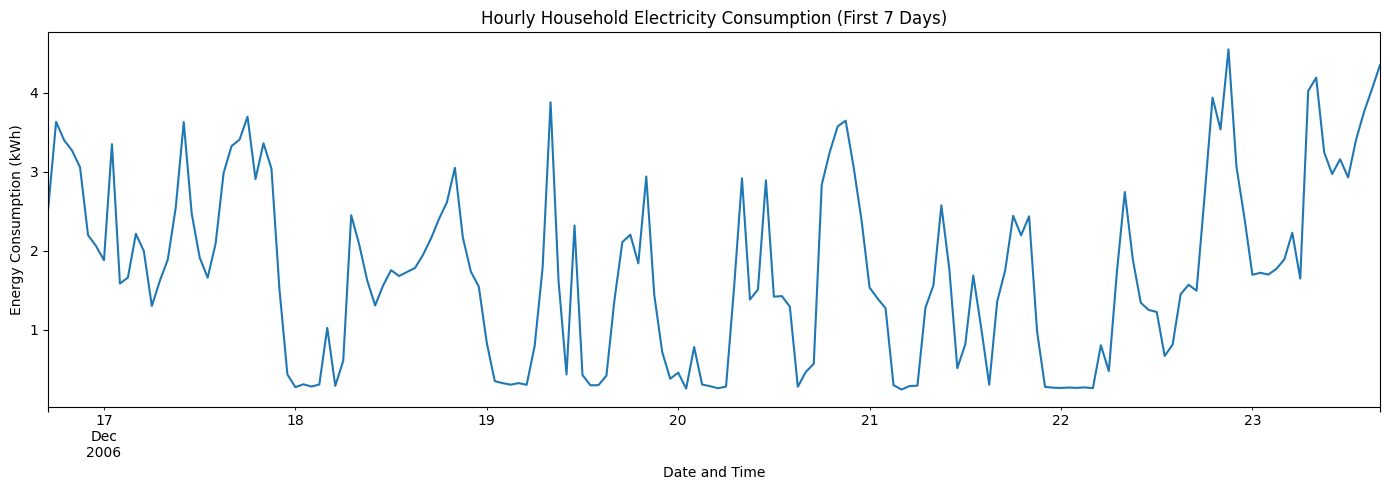

In [ ]:
import matplotlib.pyplot as plt

# 1. Select and plot the first 7 days (168 hours) of hourly energy consumption to visualize the weekly cyclic pattern
hourly_df["Hourly_energy_kWh"].iloc[:168].plot(
    figsize=(14, 5),
    title="Hourly Household Electricity Consumption (First 7 Days)",
    xlabel="Date and Time",
    ylabel="Energy Consumption (kWh)"
)

# 2. Adjust layout and render the Matplotlib visualization
plt.tight_layout()
plt.show()

In [ ]:
# 1. Reset the index to convert 'Datetime' from a row index back into a regular data column
hourly_df = hourly_df.reset_index()

# 2. Save the formatted dataframe back to a CSV file, excluding the default numerical index
hourly_df.to_csv(
    "/content/hourly_power_consumption.csv",
    index=False
)

# 3. Trigger a browser download of the updated CSV file
from google.colab import files
files.download("/content/hourly_power_consumption.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Parse index as Datetime and sort chronological order if starting with loaded file
if "Datetime" in hourly_df.columns:
    hourly_df["Datetime"] = pd.to_datetime(
        hourly_df["Datetime"], errors="coerce"
    )
    hourly_df = hourly_df.dropna(subset=["Datetime"])
    hourly_df = hourly_df.set_index("Datetime")

hourly_df = hourly_df.sort_index()

# 2. Ensure target column is numeric
target = "Hourly_energy_kWh"
hourly_df[target] = pd.to_numeric(
    hourly_df[target], errors="coerce"
)

# 3. Compute rolling median using a 24-hour centered window to form a dynamic normal baseline
window = 24
values = hourly_df[target]
baseline = values.rolling(
    window=window, center=True, min_periods=12
).median()

# 4. Calculate Rolling Median Absolute Deviation (MAD) for robust variance assessment
absolute_deviation = (values - baseline).abs()
mad = absolute_deviation.rolling(
    window=window, center=True, min_periods=12
).median()

# 5. Compute robust anomaly scores using standard scaling factor (1.4826)
scale = 1.4826 * mad
score = (values - baseline).abs() / scale.replace(0, np.nan)

hourly_df["Baseline_kWh"] = baseline
hourly_df["Anomaly_score"] = score

# 6. Flag anomalies (values outside expected variation with a threshold of 3.5)
hourly_df["High_spike"] = (
    (values > baseline) &
    (score > 3.5)
)
hourly_df["Low_anomaly"] = (
    (values < baseline) &
    (score > 3.5)
)

# 7. Print total anomalies found and display some examples
anomalies = hourly_df[
    hourly_df["High_spike"] | hourly_df["Low_anomaly"]
]
print("Total flagged records:", len(anomalies))
display(anomalies.head(20))

Total flagged records: 1593


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hourly_energy_kWh,Sub_metering_1_kWh,Sub_metering_2_kWh,Sub_metering_3_kWh,Baseline_kWh,Anomaly_score,High_spike,Low_anomaly
Datetime,,,,,,,,,,,,,,,
2006-12-28 21:00:00,5.035333,0.165700,237.294500,21.406667,640.0,1774.0,915.0,5.035333,0.640,1.774,0.915,2.141483,4.344338,True,False
2007-01-01 09:00:00,3.146133,0.067600,239.778833,13.053333,0.0,0.0,722.0,3.146133,0.000,0.000,0.722,2.465767,3.759173,True,False
2007-01-01 14:00:00,1.294400,0.241233,240.656667,5.610000,0.0,14.0,543.0,1.294400,0.000,0.014,0.543,2.035783,3.801986,False,True
2007-01-02 04:00:00,1.039967,0.094500,243.612333,4.286667,0.0,0.0,599.0,1.039967,0.000,0.000,0.599,0.446700,10.990695,True,False
2007-01-02 05:00:00,0.710600,0.116500,242.439667,3.026667,0.0,34.0,267.0,0.710600,0.000,0.034,0.267,0.446700,4.888939,True,False
2007-01-02 15:00:00,1.438100,0.141000,242.957333,5.903333,0.0,38.0,953.0,1.438100,0.000,0.038,0.953,0.619417,4.388009,True,False
2007-01-02 17:00:00,2.136200,0.261900,238.177667,9.120000,0.0,4.0,505.0,2.136200,0.000,0.004,0.505,0.493617,4.980664,True,False
2007-01-02 18:00:00,1.972067,0.228100,237.584500,8.363333,0.0,30.0,1038.0,1.972067,0.000,0.030,1.038,0.493617,7.924250,True,False
2007-01-02 20:00:00,2.573533,0.370267,238.494500,10.856667,0.0,35.0,1045.0,2.573533,0.000,0.035,1.045,0.493617,4.078943,True,False


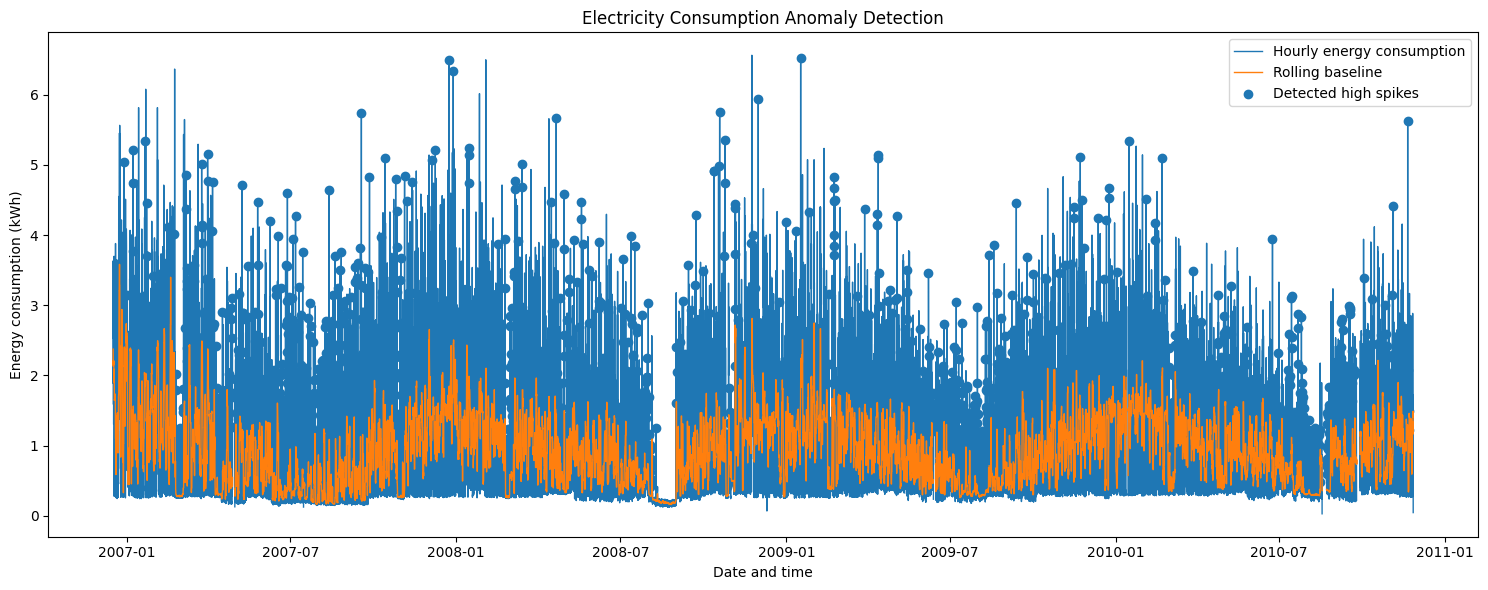

In [ ]:
plt.figure(figsize=(15, 6))

# 1. Plot the actual hourly energy consumption trend line
plt.plot(
    hourly_df.index,
    hourly_df["Hourly_energy_kWh"],
    label="Hourly energy consumption",
    linewidth=1
)

# 2. Plot the computed rolling median baseline for visual reference
plt.plot(
    hourly_df.index,
    hourly_df["Baseline_kWh"],
    label="Rolling baseline",
    linewidth=1
)

# 3. Filter for records flagged as high spikes
spikes = hourly_df[hourly_df["High_spike"]]

# 4. Overlay the high-consumption anomalies as distinct point markers on the plot
plt.scatter(
    spikes.index,
    spikes["Hourly_energy_kWh"],
    label="Detected high spikes",
    marker="o"
)

# 5. Add titles, labels, legend, and render the chart
plt.title("Electricity Consumption Anomaly Detection")
plt.xlabel("Date and time")
plt.ylabel("Energy consumption (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

# CELL 1: Connect Google Drive to Google Colab

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:

# CELL 3: Load the hourly electricity dataset from Google Drive

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = (
    "/content/drive/MyDrive/Electricity_consumption/"
    "hourly_power_consumption.csv"
)

hourly_df = pd.read_csv(file_path)

# Convert Datetime into the index
hourly_df["Datetime"] = pd.to_datetime(
    hourly_df["Datetime"], errors="coerce"
)

hourly_df = (
    hourly_df.dropna(subset=["Datetime"])
    .set_index("Datetime")
    .sort_index()
)

print("Dataset loaded successfully!")
print("Rows:", len(hourly_df))
print("Columns:", hourly_df.columns.tolist())

display(hourly_df.head())


Dataset loaded successfully!
Rows: 34589
Columns: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hourly_energy_kWh', 'Sub_metering_1_kWh', 'Sub_metering_2_kWh', 'Sub_metering_3_kWh']


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hourly_energy_kWh,Sub_metering_1_kWh,Sub_metering_2_kWh,Sub_metering_3_kWh
Datetime,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,2.533733,0.0,0.019,0.607
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,3.632200,0.0,0.403,1.012
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,3.400233,0.0,0.086,1.001
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,3.268567,0.0,0.000,1.007
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,3.056467,0.0,0.025,1.033


In [ ]:

import pandas as pd

# Your existing uploaded CSV filename
filename = "/content/hourly_power_consumption.csv"  # Replace with your actual filename

# Load CSV and skip malformed rows
hourly_df = pd.read_csv(
    filename,
    engine="python",
    on_bad_lines="warn"
)

print("Dataset loaded successfully!")
print("Shape:", hourly_df.shape)
print(hourly_df.head())
print("\nColumns:")
print(hourly_df.columns.tolist())


Dataset loaded successfully!
Shape: (34589, 12)
              Datetime  Global_active_power  Global_reactive_power  \
0  2006-12-16 17:00:00             4.222889               0.229000   
1  2006-12-16 18:00:00             3.632200               0.080033   
2  2006-12-16 19:00:00             3.400233               0.085233   
3  2006-12-16 20:00:00             3.268567               0.075100   
4  2006-12-16 21:00:00             3.056467               0.076667   

      Voltage  Global_intensity  Sub_metering_1  Sub_metering_2  \
0  234.643889         18.100000             0.0            19.0   
1  234.580167         15.600000             0.0           403.0   
2  233.232500         14.503333             0.0            86.0   
3  234.071500         13.916667             0.0             0.0   
4  237.158667         13.046667             0.0            25.0   

   Sub_metering_3  Hourly_energy_kWh  Sub_metering_1_kWh  Sub_metering_2_kWh  \
0           607.0           2.533733            

In [ ]:
# 1. Double check the dataset dimensions and verify column integrity
print("Dataset shape:", hourly_df.shape)
print("Columns:", hourly_df.columns.tolist())

# 2. Inspect the head of the processed dataset
display(hourly_df.head())

Dataset shape: (34589, 12)
Columns: ['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hourly_energy_kWh', 'Sub_metering_1_kWh', 'Sub_metering_2_kWh', 'Sub_metering_3_kWh']


,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hourly_energy_kWh,Sub_metering_1_kWh,Sub_metering_2_kWh,Sub_metering_3_kWh
0,2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,2.533733,0.0,0.019,0.607
1,2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,3.632200,0.0,0.403,1.012
2,2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,3.400233,0.0,0.086,1.001
3,2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,3.268567,0.0,0.000,1.007
4,2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,3.056467,0.0,0.025,1.033


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# Make a copy and prepare Datetime as the index if it is a column
hourly_df_temp = hourly_df.copy()
if "Datetime" in hourly_df_temp.columns:
    hourly_df_temp["Datetime"] = pd.to_datetime(hourly_df_temp["Datetime"], errors="coerce")
    hourly_df_temp = hourly_df_temp.dropna(subset=["Datetime"])
    hourly_df_temp = hourly_df_temp.set_index("Datetime")

target = "Hourly_energy_kWh"
hourly_df_temp[target] = pd.to_numeric(
    hourly_df_temp[target], errors="coerce"
)
hourly_df_temp = hourly_df_temp.sort_index()
data = hourly_df_temp[[target]].copy()

# 1. Feature Engineering: Create time-lagged historical features
data["previous_hour"] = data[target].shift(1)
data["previous_24_hours"] = data[target].shift(24)

# 2. Feature Engineering: Create rolling statistics based on prior window
data["rolling_mean_24h"] = (
    data[target].shift(1).rolling(24).mean()
)
data["rolling_std_24h"] = (
    data[target].shift(1).rolling(24).std()
)

# 3. Feature Engineering: Extract cyclic time attributes from index
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek

# 4. Clean empty records resulting from shift lags and infinity values
data = data.replace([np.inf, -np.inf], np.nan).dropna()

# 5. Select active features for training input matrix
features = [
    target,
    "previous_hour",
    "previous_24_hours",
    "rolling_mean_24h",
    "rolling_std_24h",
    "hour",
    "day_of_week"
]
X = data[features]

print("Feature preparation completed.")
print("Usable rows:", len(X))
display(X.head())

Feature preparation completed.
Usable rows: 33952


,Hourly_energy_kWh,previous_hour,previous_24_hours,rolling_mean_24h,rolling_std_24h,hour,day_of_week
Datetime,,,,,,,
2006-12-17 17:00:00,3.406767,3.326033,2.533733,2.428764,0.725646,17,6
2006-12-17 18:00:00,3.697100,3.406767,3.632200,2.465140,0.752521,18,6
2006-12-17 19:00:00,2.908400,3.697100,3.400233,2.467844,0.757001,19,6
2006-12-17 20:00:00,3.361500,2.908400,3.268567,2.447351,0.737057,20,6
2006-12-17 21:00:00,3.040767,3.361500,3.056467,2.451224,0.741788,21,6


In [ ]:
# 1. Use an 80/20 sequential chronological train-test split for time-series forecasting safety
split = int(len(X) * 0.80)

# 2. Assign the first 80% of rows for training
X_train = X.iloc[:split]

# 3. Assign the last 20% of rows for final evaluation and testing
X_test = X.iloc[split:]

# 4. Confirm the sample sizes of both resulting subsets
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 27161
Testing samples: 6791


In [ ]:
# 1. Initialize the Isolation Forest Model
# n_estimators: count of decision trees (200 is robust for stability)
# contamination: assumed proportion of outlier data (2% anomaly expectation)
model = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42
)

# 2. Fit the model onto our designated train dataset
model.fit(X_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
# 1. Align historical dataframe references with test split subset
results = data.loc[X_test.index].copy()

# 2. Predict anomalies (outputs -1 for outliers and 1 for inliers)
predictions = model.predict(X_test)

# 3. Process anomaly outcomes into legible boolean and status columns
results["Anomaly"] = predictions == -1
results["Status"] = np.where(
    results["Anomaly"],
    "Abnormal",
    "Normal"
)

# 4. Identify high spikes by checking if anomalies are greater than recent average consumption
results["High_spike"] = (
    results["Anomaly"] &
    (results[target] > results["rolling_mean_24h"])
)

print("Detection completed.")
print("\nDetection summary:")
print(results["Status"].value_counts())

print("\nDetected abnormal readings:")
display(results[results["Anomaly"]].head(20))

Detection completed.

Detection summary:
Status
Normal      6784
Abnormal       7
Name: count, dtype: int64

Detected abnormal readings:


,Hourly_energy_kWh,previous_hour,previous_24_hours,rolling_mean_24h,rolling_std_24h,hour,day_of_week,Anomaly,Status,High_spike
Datetime,,,,,,,,,,
2010-02-21 15:00:00,4.513500,4.638200,0.348433,1.495435,1.369567,15,6,True,Abnormal,True
2010-02-21 16:00:00,2.406433,4.513500,0.348333,1.668979,1.477537,16,6,True,Abnormal,True
2010-02-21 18:00:00,1.977133,3.279400,3.076300,1.872451,1.461617,18,6,True,Abnormal,True
2010-02-22 11:00:00,1.419467,1.427367,5.090800,2.145190,1.313371,11,0,True,Abnormal,False
2010-11-04 20:00:00,4.462600,4.053767,1.619033,1.600032,1.285520,20,3,True,Abnormal,True
2010-11-04 21:00:00,3.097167,4.462600,3.143167,1.718514,1.412151,21,3,True,Abnormal,True
2010-11-05 08:00:00,1.846133,2.762200,4.418900,1.764846,1.427211,8,4,True,Abnormal,True


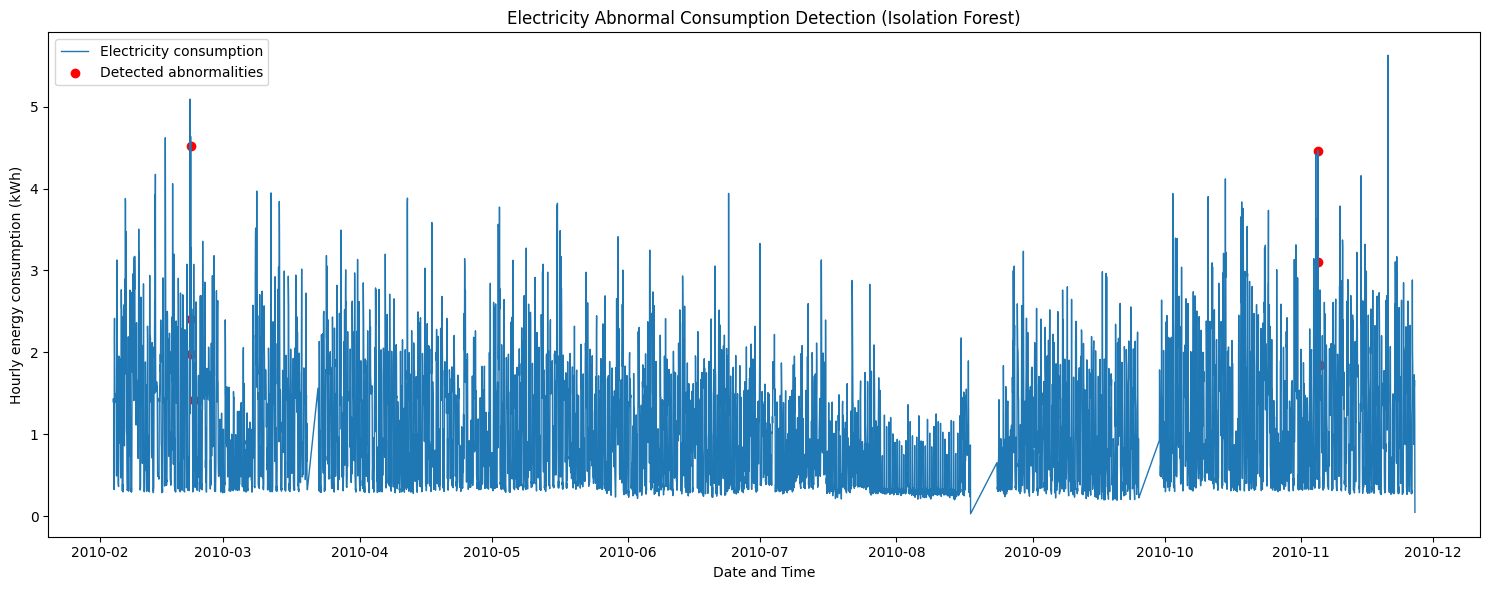

In [ ]:
plt.figure(figsize=(15, 6))

# 1. Plot the continuous real hourly energy consumption curve from the test dataset
plt.plot(
    results.index,
    results[target],
    label="Electricity consumption",
    linewidth=1
)

# 2. Isolate rows where the Isolation Forest model flagged an abnormality
abnormal = results[results["Anomaly"]]

# 3. Highlight the machine-learning-flagged anomalies using scatter point markers
plt.scatter(
    abnormal.index,
    abnormal[target],
    label="Detected abnormalities",
    marker="o",
    color="red"
)

# 4. Set plot metadata and render
plt.title("Electricity Abnormal Consumption Detection (Isolation Forest)")
plt.xlabel("Date and Time")
plt.ylabel("Hourly energy consumption (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 1. Save the final machine learning detection results dataframe to a CSV file
results.to_csv(
    "/content/electricity_anomaly_results.csv",
    index_label="Datetime"
)

# 2. Download the resulting file locally via the browser
from google.colab import files
files.download("/content/electricity_anomaly_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 1. Verify that the Isolation Forest model is successfully fitted and built
print("Model trained:", hasattr(model, "estimators_"))

# 2. Check the configured number of decision trees in the fitted forest
print("Number of trees:", len(model.estimators_))

Model trained: True
Number of trees: 200


In [ ]:

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Check whether the hourly dataset is available
# If Colab restarted, upload your CSV and load it first
print("Dataset shape:", hourly_df.shape)
print("Available columns:", hourly_df.columns.tolist())

# Display the first five rows
display(hourly_df.head())


Dataset shape: (34589, 12)
Available columns: ['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hourly_energy_kWh', 'Sub_metering_1_kWh', 'Sub_metering_2_kWh', 'Sub_metering_3_kWh']


,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hourly_energy_kWh,Sub_metering_1_kWh,Sub_metering_2_kWh,Sub_metering_3_kWh
0,2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,2.533733,0.0,0.019,0.607
1,2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,3.632200,0.0,0.403,1.012
2,2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,3.400233,0.0,0.086,1.001
3,2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,3.268567,0.0,0.000,1.007
4,2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,3.056467,0.0,0.025,1.033


In [ ]:

# Make a copy so the original dataset remains unchanged
forecast_df = hourly_df.copy()

# If Datetime is a normal column, convert it to the index
if "Datetime" in forecast_df.columns:
    forecast_df["Datetime"] = pd.to_datetime(
        forecast_df["Datetime"], errors="coerce"
    )
    forecast_df = forecast_df.dropna(subset=["Datetime"])
    forecast_df = forecast_df.set_index("Datetime")

# Sort readings chronologically
forecast_df = forecast_df.sort_index()

# Select the energy consumption column
target = "Hourly_energy_kWh"

# Convert consumption values to numeric
forecast_df[target] = pd.to_numeric(
    forecast_df[target], errors="coerce"
)

# Remove missing or invalid target readings
forecast_df = forecast_df.dropna(subset=[target])

# Display the cleaned dataset information
print("Cleaned dataset shape:", forecast_df.shape)
print("Start time:", forecast_df.index.min())
print("End time:", forecast_df.index.max())

display(forecast_df.head())


Cleaned dataset shape: (34168, 11)
Start time: 2006-12-16 17:00:00
End time: 2010-11-26 21:00:00


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hourly_energy_kWh,Sub_metering_1_kWh,Sub_metering_2_kWh,Sub_metering_3_kWh
Datetime,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,2.533733,0.0,0.019,0.607
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,3.632200,0.0,0.403,1.012
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,3.400233,0.0,0.086,1.001
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,3.268567,0.0,0.000,1.007
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,3.056467,0.0,0.025,1.033


In [ ]:

# Create a new DataFrame for forecasting features
data = forecast_df[[target]].copy()

# Add previous electricity consumption values (lag features)
data["lag_1"] = data[target].shift(1)      # Previous hour
data["lag_2"] = data[target].shift(2)      # Two hours earlier
data["lag_3"] = data[target].shift(3)      # Three hours earlier
data["lag_24"] = data[target].shift(24)    # Same hour yesterday
data["lag_168"] = data[target].shift(168)  # Same hour last week

# Calculate rolling averages using only previous readings
data["rolling_mean_24"] = (
    data[target].shift(1).rolling(24).mean()
)

data["rolling_mean_168"] = (
    data[target].shift(1).rolling(168).mean()
)

# Extract time-related features
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek
data["month"] = data.index.month

# Set the target to the NEXT hour's energy consumption
data["target_next_hour"] = data[target].shift(-1)

# Replace infinite values and remove rows with missing features
data = data.replace([np.inf, -np.inf], np.nan).dropna()

# Select the input features for the model
features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168",
    "hour",
    "day_of_week",
    "month"
]

# X contains the input features; y contains the next-hour target
X = data[features]
y = data["target_next_hour"]

print("Feature preparation completed.")
print("Number of samples:", len(X))
print("Number of features:", len(features))

display(X.head())


Feature preparation completed.
Number of samples: 33999
Number of features: 10


,lag_1,lag_2,lag_3,lag_24,lag_168,rolling_mean_24,rolling_mean_168,hour,day_of_week,month
Datetime,,,,,,,,,,
2006-12-23 17:00:00,4.349100,4.049100,3.757967,1.496800,2.533733,2.934890,1.753785,17,5,12
2006-12-23 18:00:00,5.452533,4.349100,4.049100,2.686967,3.632200,3.099713,1.771159,18,5,12
2006-12-23 19:00:00,3.879400,5.452533,4.349100,3.938167,3.400233,3.149397,1.772630,19,5,12
2006-12-23 20:00:00,4.117833,3.879400,5.452533,3.536067,3.268567,3.156883,1.776902,20,5,12
2006-12-23 21:00:00,4.181400,4.117833,3.879400,4.548667,3.056467,3.183772,1.782335,21,5,12


In [ ]:

# Calculate the position at which to split the data
split = int(len(X) * 0.80)

# Earlier observations are used for training
X_train = X.iloc[:split]
y_train = y.iloc[:split]

# Later observations are reserved for testing
X_test = X.iloc[split:]
y_test = y.iloc[split:]

# Display the sizes of the datasets
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())


Training samples: 27199
Testing samples: 6800
Training period: 2006-12-23 17:00:00 to 2010-02-06 13:00:00
Testing period: 2010-02-06 14:00:00 to 2010-11-26 20:00:00


In [ ]:

# Install the XGBoost machine-learning library
%pip -q install xgboost


In [ ]:

# Import the XGBoost regression model
from xgboost import XGBRegressor

# Create the forecasting model
forecast_model = XGBRegressor(
    n_estimators=300,          # Number of boosting trees
    max_depth=6,               # Maximum depth of each tree
    learning_rate=0.05,        # Learning rate for boosting
    objective="reg:squarederror",
    random_state=42,            # Make results reproducible
    n_jobs=-1                   # Use available CPU cores
)

# Train the model using historical data
forecast_model.fit(X_train, y_train)

# Confirm that training has completed
print("Electricity forecasting model trained successfully!")


Electricity forecasting model trained successfully!


In [ ]:

# Generate predictions using the trained forecasting model
y_pred = forecast_model.predict(X_test)

# Create a table comparing actual and predicted consumption
prediction_results = pd.DataFrame(
    {
        "Actual_kWh": y_test,
        "Predicted_kWh": y_pred
    },
    index=y_test.index
)

# Calculate the absolute prediction error for each hour
prediction_results["Absolute_Error_kWh"] = (
    prediction_results["Actual_kWh"]
    - prediction_results["Predicted_kWh"]
).abs()

# Save the results to a CSV file
output_path = "/content/electricity_forecast_test_results.csv"

prediction_results.to_csv(
    output_path,
    index_label="Datetime"
)

print("Test predictions saved:", output_path)

# Download the results to your computer
from google.colab import files
files.download(output_path)


Test predictions saved: /content/electricity_forecast_test_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

# Create a comparison table
comparison = pd.DataFrame({
    "Actual_kWh": y_test,
    "Predicted_kWh": y_pred
})

# Calculate absolute error for every prediction
comparison["Absolute_Error"] = (
    comparison["Actual_kWh"] - comparison["Predicted_kWh"]
).abs()

# Display the first 20 predictions
display(comparison.head(20))


,Actual_kWh,Predicted_kWh,Absolute_Error
Datetime,,,
2010-02-06 14:00:00,2.893133,1.368937,1.524197
2010-02-06 15:00:00,2.820700,1.867789,0.952911
2010-02-06 16:00:00,1.737833,2.309527,0.571694
2010-02-06 17:00:00,3.877433,3.465934,0.411499
2010-02-06 18:00:00,3.840000,3.488837,0.351163
2010-02-06 19:00:00,2.558233,3.242462,0.684229
2010-02-06 20:00:00,2.988300,2.950547,0.037753
2010-02-06 21:00:00,2.849100,2.173612,0.675488
2010-02-06 22:00:00,3.474900,2.360209,1.114691


In [ ]:

# CELL 2: Create input features and the next-hour prediction target.
# Historical readings are used as inputs; the next hour's energy is the target.

# Ensure Datetime is converted to datetime and set as index first
if 'Datetime' in hourly_df.columns:
    hourly_df['Datetime'] = pd.to_datetime(hourly_df['Datetime'], errors='coerce')
    hourly_df = hourly_df.dropna(subset=['Datetime']).set_index('Datetime')

data = hourly_df[[target]].copy()

# Previous electricity consumption
data["lag_1"] = data[target].shift(1)
data["lag_2"] = data[target].shift(2)
data["lag_3"] = data[target].shift(3)
data["lag_24"] = data[target].shift(24)
data["lag_168"] = data[target].shift(168)

# Rolling averages based only on earlier observations
data["rolling_mean_24"] = (
    data[target].shift(1).rolling(24).mean()
)

data["rolling_mean_168"] = (
    data[target].shift(1).rolling(168).mean()
)

# Time-related features
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek
data["month"] = data.index.month

# Predict consumption in the next hour
data["target_next_hour"] = data[target].shift(-1)

# Remove rows with missing or invalid features
data = data.replace([np.inf, -np.inf], np.nan).dropna()

features = [
    "lag_1", "lag_2", "lag_3", "lag_24", "lag_168",
    "rolling_mean_24", "rolling_mean_168",
    "hour", "day_of_week", "month"
]

X = data[features]
y = data["target_next_hour"]

print("Feature preparation completed.")
print("Total usable samples:", len(X))
print("Number of input features:", len(features))

display(X.head())


Feature preparation completed.
Total usable samples: 32647
Number of input features: 10


,lag_1,lag_2,lag_3,lag_24,lag_168,rolling_mean_24,rolling_mean_168,hour,day_of_week,month
Datetime,,,,,,,,,,
2006-12-23 17:00:00,4.349100,4.049100,3.757967,1.496800,2.533733,2.934890,1.753785,17,5,12
2006-12-23 18:00:00,5.452533,4.349100,4.049100,2.686967,3.632200,3.099713,1.771159,18,5,12
2006-12-23 19:00:00,3.879400,5.452533,4.349100,3.938167,3.400233,3.149397,1.772630,19,5,12
2006-12-23 20:00:00,4.117833,3.879400,5.452533,3.536067,3.268567,3.156883,1.776902,20,5,12
2006-12-23 21:00:00,4.181400,4.117833,3.879400,4.548667,3.056467,3.183772,1.782335,21,5,12


In [ ]:

# CELL 3: Split the data chronologically into training and testing sets.
# The test set represents a later period that the model has not trained on.

split = int(len(X) * 0.80)

X_train = X.iloc[:split]
y_train = y.iloc[:split]

X_test = X.iloc[split:]
y_test = y.iloc[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())


Training samples: 26117
Testing samples: 6530
Training period: 2006-12-23 17:00:00 to 2010-01-27 16:00:00
Testing period: 2010-01-27 17:00:00 to 2010-11-26 20:00:00


In [ ]:


# CELL 5: Train an XGBoost regression model on the training data.
# The model learns relationships between past consumption, time features, and next-hour energy.

from xgboost import XGBRegressor

forecast_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

forecast_model.fit(X_train, y_train)

print("XGBoost forecasting model trained successfully!")



XGBoost forecasting model trained successfully!


In [ ]:

# CELL 6: Evaluate next-hour predictions using standard regression metrics.
# Lower MAE, MSE, and RMSE are generally better; compare R² against a baseline.

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred = forecast_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== MODEL PERFORMANCE =====")
print(f"MAE  : {mae:.4f} kWh")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f} kWh")
print(f"R²   : {r2:.4f}")


===== MODEL PERFORMANCE =====
MAE  : 0.4077 kWh
MSE  : 0.3167
RMSE : 0.5628 kWh
R²   : 0.4493


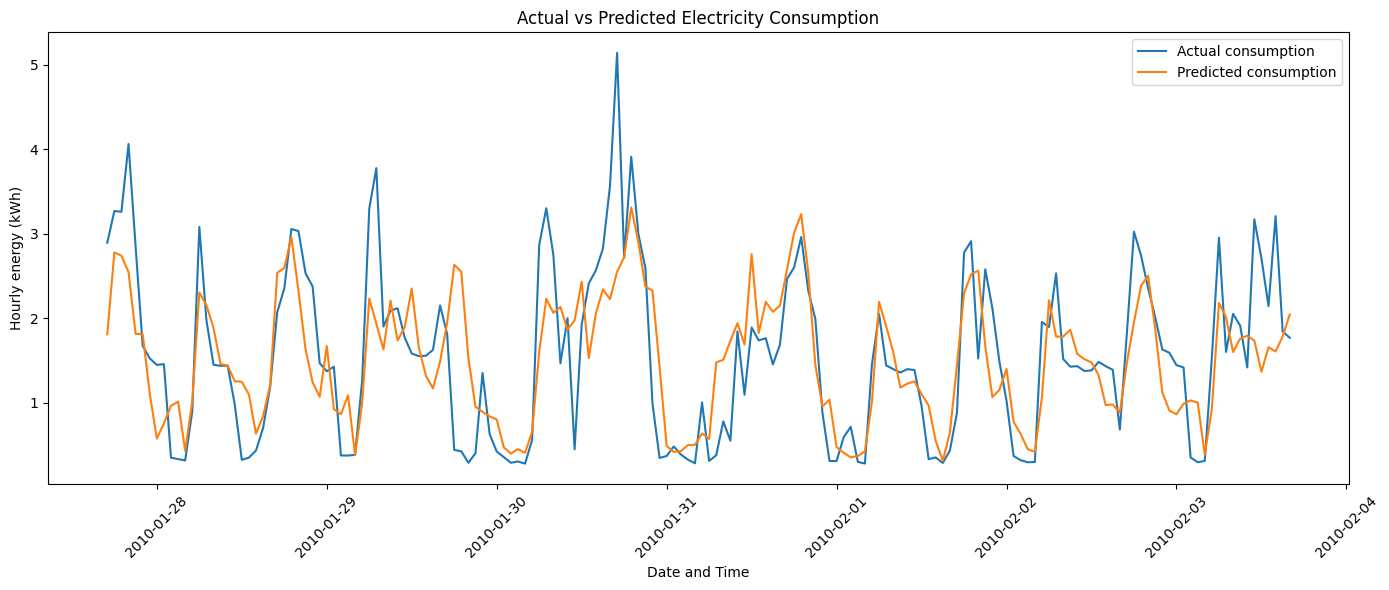

In [ ]:

# CELL 7: Plot actual and predicted electricity consumption on the test period.
# This visualizes historical test performance, not future dates beyond the dataset.

plot_count = min(168, len(y_test))

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index[:plot_count],
    y_test.iloc[:plot_count],
    label="Actual consumption"
)

plt.plot(
    y_test.index[:plot_count],
    y_pred[:plot_count],
    label="Predicted consumption"
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Date and Time")
plt.ylabel("Hourly energy (kWh)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# CELL 8: Forecast future hourly consumption and flag potential high spikes.
# Each predicted hour is added to the history before predicting the next hour.
# Spike flags are heuristic warnings, not confirmed faults or probabilities.

forecast_horizon = 24  # Change to 168 for 7 days or 720 for 30 days

history = hourly_df[target].dropna().astype(float).tolist()

if len(history) < 168:
    raise ValueError("At least 168 historical hourly readings are required.")

future_predictions = []

for step in range(forecast_horizon):

    # Build lag features from historical readings and previous predictions
    next_time = (
        hourly_df.index[-1] + pd.Timedelta(hours=step + 1)
    )

    future_features = pd.DataFrame([{
        "lag_1": history[-1],
        "lag_2": history[-2],
        "lag_3": history[-3],
        "lag_24": history[-24],
        "lag_168": history[-168],
        "rolling_mean_24": np.mean(history[-24:]),
        "rolling_mean_168": np.mean(history[-168:]),
        "hour": next_time.hour,
        "day_of_week": next_time.dayofweek,
        "month": next_time.month
    }])

    # Predict the next hour and keep energy non-negative
    prediction = max(
        0.0,
        float(forecast_model.predict(future_features)[0])
    )

    future_predictions.append(prediction)
    history.append(prediction)

# Create the future forecast DataFrame
future_index = pd.date_range(
    start=hourly_df.index[-1] + pd.Timedelta(hours=1),
    periods=forecast_horizon,
    freq="h"
)

future_df = pd.DataFrame(
    {"Predicted_energy_kWh": future_predictions},
    index=future_index
)

future_df.index.name = "Datetime"

# Calculate historical median and MAD for each hour of the day
historical = hourly_df[target].dropna()

hourly_median = historical.groupby(
    historical.index.hour
).median()

hourly_mad = historical.groupby(
    historical.index.hour
).apply(
    lambda s: np.median(
        np.abs(s - np.median(s))
    )
)

# Add historical reference values for each forecasted hour
future_df["Typical_energy_kWh"] = [
    hourly_median.get(t.hour, np.nan)
    for t in future_df.index
]

future_df["Historical_MAD"] = [
    hourly_mad.get(t.hour, np.nan)
    for t in future_df.index
]

# Flag unusually high predictions using a robust historical threshold
threshold = (
    future_df["Typical_energy_kWh"]
    + 3 * 1.4826 * future_df["Historical_MAD"]
)

future_df["Potential_spike"] = (
    future_df["Predicted_energy_kWh"] > threshold
).fillna(False)

future_df["Status"] = np.where(
    future_df["Potential_spike"],
    "Potential abnormal spike",
    "No spike flagged"
)

print("Future forecasting completed.")
print("Forecast horizon:", forecast_horizon, "hours")
print("Potential spikes:", int(future_df["Potential_spike"].sum()))

display(future_df)


Future forecasting completed.
Forecast horizon: 24 hours
Potential spikes: 1


,Predicted_energy_kWh,Typical_energy_kWh,Historical_MAD,Potential_spike,Status
Datetime,,,,,
2010-11-26 22:00:00,0.402812,1.311450,0.601550,False,No spike flagged
2010-11-26 23:00:00,0.900422,0.637650,0.310933,False,No spike flagged
2010-11-27 00:00:00,0.576579,0.391967,0.108300,False,No spike flagged
2010-11-27 01:00:00,0.488988,0.347333,0.071667,False,No spike flagged
2010-11-27 02:00:00,0.465941,0.332083,0.056183,False,No spike flagged
2010-11-27 03:00:00,0.476549,0.325083,0.050550,False,No spike flagged
2010-11-27 04:00:00,0.522660,0.325217,0.053767,False,No spike flagged
2010-11-27 05:00:00,0.762535,0.323267,0.055900,True,Potential abnormal spike
2010-11-27 06:00:00,1.803721,0.678667,0.352400,False,No spike flagged


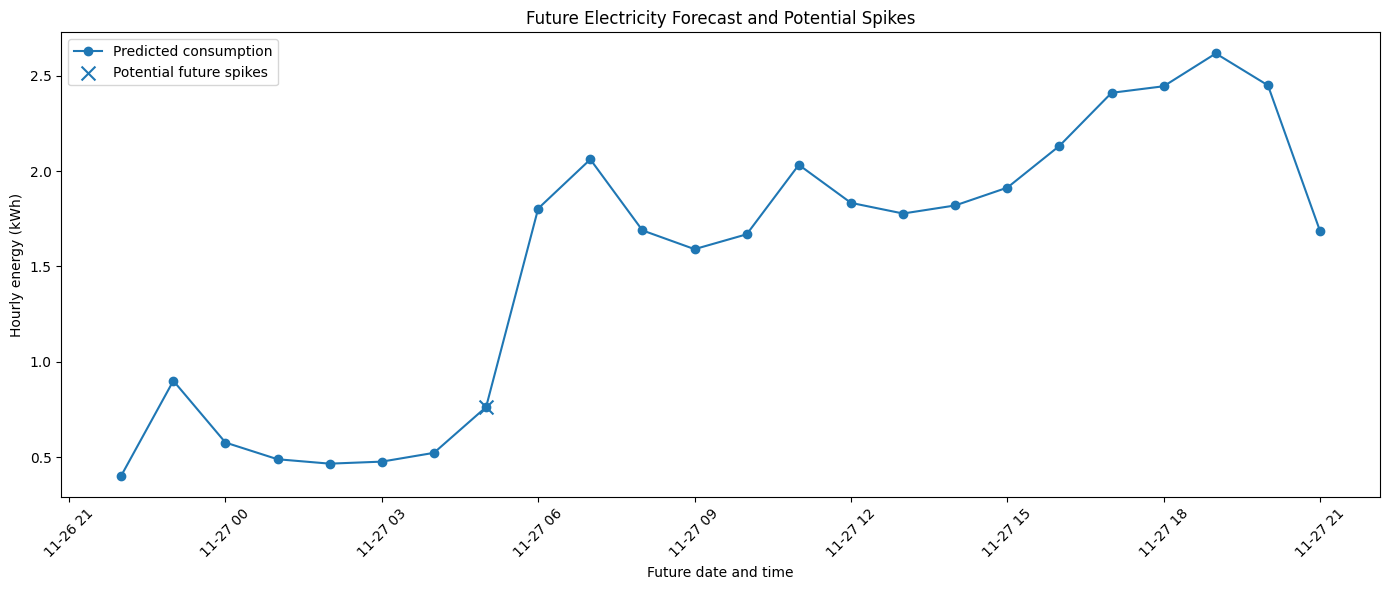

In [ ]:

# CELL 9: Visualize predicted future consumption and potential spikes.

plt.figure(figsize=(14, 6))

plt.plot(
    future_df.index,
    future_df["Predicted_energy_kWh"],
    marker="o",
    label="Predicted consumption"
)

spikes = future_df[future_df["Potential_spike"]]

plt.scatter(
    spikes.index,
    spikes["Predicted_energy_kWh"],
    marker="x",
    s=100,
    label="Potential future spikes"
)

plt.title("Future Electricity Forecast and Potential Spikes")
plt.xlabel("Future date and time")
plt.ylabel("Hourly energy (kWh)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# CELL 10: Save future forecasts and potential spike flags to Google Drive.
# Ensure Cell 1 successfully mounted Drive and the folder exists.

import os

output_folder = (
    "/content/drive/MyDrive/Electricity_consumption"
)

os.makedirs(output_folder, exist_ok=True)

output_path = os.path.join(
    output_folder,
    "future_electricity_forecast.csv"
)

future_df.to_csv(output_path, index_label="Datetime")

print("Forecast results saved successfully!")
print("File location:", output_path)


Forecast results saved successfully!
File location: /content/drive/MyDrive/Electricity_consumption/future_electricity_forecast.csv


In [ ]:
# CELL: Configure separate weekly and monthly forecasts

WEEKLY_HOURS = 7 * 24       # 168 hours
MONTHLY_HOURS = 30 * 24     # 720 hours

print("Weekly forecast:", WEEKLY_HOURS, "hours")
print("Monthly forecast:", MONTHLY_HOURS, "hours")

Weekly forecast: 168 hours
Monthly forecast: 720 hours


In [ ]:

# CELL: Define the future forecasting function
# Predict electricity consumption and flag potential spikes.

import pandas as pd
import numpy as np

TARGET = "Hourly_energy_kWh"

def generate_forecast(horizon):
    history = hourly_df[TARGET].dropna().astype(float).copy()

    if len(history) < 169:
        raise ValueError(
            "At least 169 hourly readings are needed for lag features."
        )

    # Historical spike thresholds for each hour of the day
    hour_stats = history.groupby(history.index.hour).agg(
        median="median",
        mad=lambda x: np.median(np.abs(x - np.median(x)))
    )

    predictions = []
    future_times = []
    spike_flags = []

    for _ in range(horizon):
        next_time = history.index[-1] + pd.Timedelta(hours=1)

        # Build features in the same order used during model training
        features = pd.DataFrame([{
            "lag_1": history.iloc[-1],
            "lag_2": history.iloc[-2],
            "lag_3": history.iloc[-3],
            "lag_24": history.iloc[-24],
            "lag_168": history.iloc[-168],
            "rolling_mean_24": history.iloc[-24:].mean(),
            "rolling_mean_168": history.iloc[-168:].mean(),
            "hour": next_time.hour,
            "day_of_week": next_time.dayofweek,
            "month": next_time.month
        }])

        # Predict the next hour
        prediction = float(forecast_model.predict(features)[0])
        prediction = max(0, prediction)

        # Compare with historical values for the same hour
        median = hour_stats.loc[next_time.hour, "median"]
        mad = hour_stats.loc[next_time.hour, "mad"]

        # Robust threshold: median + 3 scaled MADs
        threshold = median + 3 * 1.4826 * mad
        is_spike = prediction > threshold

        predictions.append(prediction)
        future_times.append(next_time)
        spike_flags.append(is_spike)

        # Feed prediction into history for the next forecast step
        history.loc[next_time] = prediction

    result = pd.DataFrame({
        "Datetime": future_times,
        "Predicted_energy_kWh": predictions,
        "Potential_spike": spike_flags
    })

    result["Status"] = np.where(
        result["Potential_spike"],
        "Potential Spike",
        "Normal"
    )

    return result.set_index("Datetime")


In [ ]:

# CELL: Generate separate weekly and monthly forecasts

WEEKLY_HOURS = 7 * 24
MONTHLY_HOURS = 30 * 24

weekly_forecast = generate_forecast(WEEKLY_HOURS)
monthly_forecast = generate_forecast(MONTHLY_HOURS)

print("WEEKLY FORECAST — NEXT 7 DAYS")
display(weekly_forecast)

print("MONTHLY FORECAST — NEXT 30 DAYS")
display(monthly_forecast)


WEEKLY FORECAST — NEXT 7 DAYS


,Predicted_energy_kWh,Potential_spike,Status
Datetime,,,
2010-11-26 22:00:00,0.402812,False,Normal
2010-11-26 23:00:00,0.900422,False,Normal
2010-11-27 00:00:00,0.576579,False,Normal
2010-11-27 01:00:00,0.488988,False,Normal
2010-11-27 02:00:00,0.465941,False,Normal
...,...,...,...
2010-12-03 17:00:00,2.220686,False,Normal
2010-12-03 18:00:00,2.306259,False,Normal
2010-12-03 19:00:00,2.473589,False,Normal


MONTHLY FORECAST — NEXT 30 DAYS


,Predicted_energy_kWh,Potential_spike,Status
Datetime,,,
2010-11-26 22:00:00,0.402812,False,Normal
2010-11-26 23:00:00,0.900422,False,Normal
2010-11-27 00:00:00,0.576579,False,Normal
2010-11-27 01:00:00,0.488988,False,Normal
2010-11-27 02:00:00,0.465941,False,Normal
...,...,...,...
2010-12-26 17:00:00,2.891240,True,Potential Spike
2010-12-26 18:00:00,3.035098,False,Normal
2010-12-26 19:00:00,2.849042,False,Normal


In [ ]:

# CELL: Display only potential spikes in weekly and monthly forecasts

weekly_spikes = weekly_forecast[
    weekly_forecast["Potential_spike"] == True
]

monthly_spikes = monthly_forecast[
    monthly_forecast["Potential_spike"] == True
]

print("WEEKLY FORECAST — POTENTIAL SPIKES")
if weekly_spikes.empty:
    print("No potential spikes detected in the next 7 days.")
else:
    display(weekly_spikes)

print("MONTHLY FORECAST — POTENTIAL SPIKES")
if monthly_spikes.empty:
    print("No potential spikes detected in the next 30 days.")
else:
    display(monthly_spikes)


WEEKLY FORECAST — POTENTIAL SPIKES


,Predicted_energy_kWh,Potential_spike,Status
Datetime,,,
2010-11-27 05:00:00,0.762535,True,Potential Spike
2010-11-28 05:00:00,0.646445,True,Potential Spike
2010-11-28 16:00:00,2.277812,True,Potential Spike
2010-11-28 17:00:00,2.891240,True,Potential Spike
2010-11-29 05:00:00,1.026748,True,Potential Spike
2010-11-30 05:00:00,1.071709,True,Potential Spike
2010-12-01 05:00:00,1.088739,True,Potential Spike
2010-12-02 05:00:00,1.115219,True,Potential Spike
2010-12-03 05:00:00,1.094745,True,Potential Spike


MONTHLY FORECAST — POTENTIAL SPIKES


,Predicted_energy_kWh,Potential_spike,Status
Datetime,,,
2010-11-27 05:00:00,0.762535,True,Potential Spike
2010-11-28 05:00:00,0.646445,True,Potential Spike
2010-11-28 16:00:00,2.277812,True,Potential Spike
2010-11-28 17:00:00,2.891240,True,Potential Spike
2010-11-29 05:00:00,1.026748,True,Potential Spike
2010-11-30 05:00:00,1.071709,True,Potential Spike
2010-12-01 05:00:00,1.088739,True,Potential Spike
2010-12-02 05:00:00,1.115219,True,Potential Spike
2010-12-03 05:00:00,1.094745,True,Potential Spike


In [ ]:

# CELL: Electricity Forecasting Visualization Dashboard
# Shows weekly/monthly forecasts, potential spikes, and summary statistics.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

def show_forecast_dashboard(period):
    forecast = (
        weekly_forecast.copy()
        if period == "Weekly (7 days)"
        else monthly_forecast.copy()
    )

    forecast.index = pd.to_datetime(forecast.index)
    forecast = forecast.sort_index()

    # Identify potential spike timestamps
    spikes = forecast[forecast["Potential_spike"] == True]

    # Summary statistics
    peak_time = forecast["Predicted_energy_kWh"].idxmax()
    peak_value = forecast["Predicted_energy_kWh"].max()

    print(f"⚡ {period.upper()} ELECTRICITY FORECAST")
    print(f"Forecast hours: {len(forecast)}")
    print(f"Potential spikes detected: {len(spikes)}")
    print(f"Highest predicted consumption: {peak_value:.3f} kWh")
    print(f"Peak forecast time: {peak_time}")

    # Plot forecast and highlight potential spikes
    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        forecast.index,
        forecast["Predicted_energy_kWh"],
        label="Predicted consumption",
        linewidth=1.8
    )

    if not spikes.empty:
        ax.scatter(
            spikes.index,
            spikes["Predicted_energy_kWh"],
            color="red",
            marker="o",
            s=65,
            label="Potential spikes",
            zorder=3
        )

    ax.set_title(f"{period} Electricity Consumption Forecast")
    ax.set_xlabel("Future date and time")
    ax.set_ylabel("Predicted energy (kWh)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    # Show only the detected spike records
    print("POTENTIAL SPIKE DETAILS")
    if spikes.empty:
        print("No potential spikes flagged for this forecast period.")
    else:
        display(spikes)

period_selector = widgets.Dropdown(
    options=["Weekly (7 days)", "Monthly (30 days)"],
    value="Weekly (7 days)",
    description="Forecast:"
)

output = widgets.interactive_output(
    show_forecast_dashboard,
    {"period": period_selector}
)

display(period_selector, output)


Dropdown(description='Forecast:', options=('Weekly (7 days)', 'Monthly (30 days)'), value='Weekly (7 days)')

Output()

In [ ]:

# CELL: Save weekly and monthly forecasts

output_dir = "/content/drive/MyDrive/Electricity_consumption"

weekly_forecast.to_csv(
    f"{output_dir}/weekly_electricity_forecast.csv"
)

monthly_forecast.to_csv(
    f"{output_dir}/monthly_electricity_forecast.csv"
)

print("Both forecast files saved successfully!")


Both forecast files saved successfully!


In [1]:
# 1. Zip all your project files (change '/content' to your specific folder if needed)
!zip -r /content/colab_files.zip /content/ -x "/content/sample_data/*"

# 2. Trigger automatic download to your computer
from google.colab import files
files.download('/content/colab_files.zip')

  adding: content/ (stored 0%)
  adding: content/.config/ (stored 0%)
  adding: content/.config/.last_opt_in_prompt.yaml (stored 0%)
  adding: content/.config/active_config (stored 0%)
  adding: content/.config/default_configs.db (deflated 98%)
  adding: content/.config/.last_survey_prompt.yaml (stored 0%)
  adding: content/.config/.last_update_check.json (deflated 22%)
  adding: content/.config/config_sentinel (stored 0%)
  adding: content/.config/gce (stored 0%)
  adding: content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db (deflated 97%)
  adding: content/.config/configurations/ (stored 0%)
  adding: content/.config/configurations/config_default (deflated 15%)
  adding: content/.config/logs/ (stored 0%)
  adding: content/.config/logs/2026.10.26/ (stored 0%)
  adding: content/.config/logs/2026.10.26/22.18.53.588181.log (deflated 56%)
  adding: content/.config/logs/2026.10.26/22.18.15.518759.log (deflated 92%)
  adding: content/.config/logs/2026.10.26/22.18.3

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>